In [1]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
from scipy.optimize import linprog
import matplotlib.pyplot as plt

In [2]:
# correlation with known points
df = pd.read_csv("data.csv")
EXCLUDE_ZERO_SALES = False

results = []
for company, g in df[df["company"] != "total"].groupby("company"):
    g = g.dropna(subset=["sales"])
    if EXCLUDE_ZERO_SALES:
        g = g[g["sales"] != 0]

    n = len(g)
    r, _ = pearsonr(g["sales"], g["google_trend_values"])
    b_hat, a_hat = np.polyfit(g["google_trend_values"], g["sales"], 1)   # slope, intercept

    results.append({
        "company": company,
        "n_quarters": n,
        "pearson_r": round(r, 3),
        "a_intercept": round(a_hat, 4),
        "b_slope": round(b_hat, 4),
        "equation": f"s = {a_hat:.4f} + {b_hat:.4f}·v",
    })

corr = pd.DataFrame(results).sort_values("pearson_r", ascending=False)
print(corr.to_string(index=False))


                                     company  n_quarters  pearson_r  a_intercept  b_slope                equation
                              Infinix Mobile          15      1.000      -0.0004   0.1308  s = -0.0004 + 0.1308·v
                           Motorola Mobility           3      0.992      -1.0500   4.7500  s = -1.0500 + 4.7500·v
                          BlackBerry Limited          26      0.989      -0.4162   0.1438  s = -0.4162 + 0.1438·v
                                 Itel Mobile          25      0.965      -0.4373   0.1537  s = -0.4373 + 0.1537·v
                             HTC Corporation           7      0.951      -3.6113   0.2015  s = -3.6113 + 0.2015·v
                Transsion Holdings Co., Ltd.          28      0.939       0.8063   0.6609   s = 0.8063 + 0.6609·v
     Vivo Communication Technology Co., Ltd.          45      0.924       2.1427   1.7480   s = 2.1427 + 1.7480·v
                                Tecno Mobile          32      0.922       0.3787   0.110

In [3]:
EPS = 1e-4

# Regression parameters per company, taken directly from the corr DataFrame above
corr_i = corr.set_index("company")
N = len(corr_i)

# Known market total T_t
T = df[df["company"] == "total"].set_index("id")["sales"]

# Companies only, with preliminary estimate s_hat = a + b*v  (eq. 4.10)
comp = df[df["company"] != "total"].copy()
comp = comp.join(corr_i[["n_quarters", "pearson_r", "a_intercept", "b_slope"]], on="company")
comp["s_hat"] = comp["a_intercept"] + comp["b_slope"] * comp["google_trend_values"]
comp["s_hat"] = comp["s_hat"].clip(lower=EPS)      # keeps the band width positive

rows = []
for t, g in comp.groupby("id"):
    miss = g[g["sales"].isna()]
    m = len(miss)
    if m == 0:
        continue

    R = T[t] - g["sales"].sum()                    # T_t - sum of known sales (eq. 4.2)
    s = miss["s_hat"].to_numpy()
    lam = ((1 - miss["pearson_r"] ** 2) / miss["n_quarters"] * (m - 1) / N).to_numpy()  # eq. 4.12

    if m == 1:                                     # lambda = 0: eq. 4.2 alone gives the value
        x, alpha = np.array([max(R, EPS)]), 1.0
    else:
        # variables: [x_1 ... x_m, alpha]; minimise alpha (eq. 4.1)
        c = np.r_[np.zeros(m), 1]

        # eq. 4.3:  x - alpha*lam*s <= s     eq. 4.4: -x - alpha*lam*s <= -s
        A_ub = np.zeros((2 * m, m + 1))
        A_ub[:m, :m] = np.eye(m)
        A_ub[m:, :m] = -np.eye(m)
        A_ub[:, -1] = -np.r_[lam * s, lam * s]
        b_ub = np.r_[s, -s]

        # eq. 4.2: sum x = R
        A_eq = np.r_[np.ones(m), 0].reshape(1, -1)

        # eq. 4.5: x >= eps, alpha >= 1
        bounds = [(EPS, None)] * m + [(1, None)]

        res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=[R], bounds=bounds)
        if not res.success:
            print(f"LP infeasible at id={t}")
            continue
        x, alpha = res.x[:m], res.x[-1]

    # CIs centred on x (eq. 4.6 - 4.7)
    ci_lo = np.maximum(x * (1 - alpha * lam), 0)
    ci_hi = x * (1 + alpha * lam)

    for i, comp_name in enumerate(miss["company"]):
        rows.append({"id": t, "company": comp_name, "imputed": x[i],
                     "ci_lower": ci_lo[i], "ci_upper": ci_hi[i], "alpha": alpha})

imp = pd.DataFrame(rows)

final = comp[["id", "years", "quarters", "company", "sales"]].merge(imp, on=["id", "company"], how="left")
final["sales_filled"] = final["sales"].fillna(final["imputed"])
final = final.sort_values(["id", "company"])

print(final[final["imputed"].notna()].head(20).to_string(index=False))


LP infeasible at id=59
LP infeasible at id=60
 id  years  quarters                                 company  sales   imputed  ci_lower  ci_upper      alpha  sales_filled
  4   2009         4                         HTC Corporation    NaN  2.977317  1.013459  4.941175 200.091962      2.977317
  4   2009         4           Huawei Technologies Co., Ltd.    NaN  0.000100  0.000076  0.000124 200.091962      0.000100
  4   2009         4              Meizu Technology Co., Ltd.    NaN  0.000100  0.000000  0.000821 200.091962      0.000100
  4   2009         4                                Micromax    NaN  0.000100  0.000000  0.000321 200.091962      0.000100
  4   2009         4                       Motorola Mobility    NaN  2.750731  2.045005  3.456456 200.091962      2.750731
  4   2009         4           Samsung Electronics Co., Ltd.    NaN  7.971452  0.973876 14.969028 200.091962      7.971452
  4   2009         4                        Sony Corporation    NaN  0.000100  0.000000  0.00

C:\Users\Merye\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\matplotlib\cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
C:\Users\Merye\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\matplotlib\cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


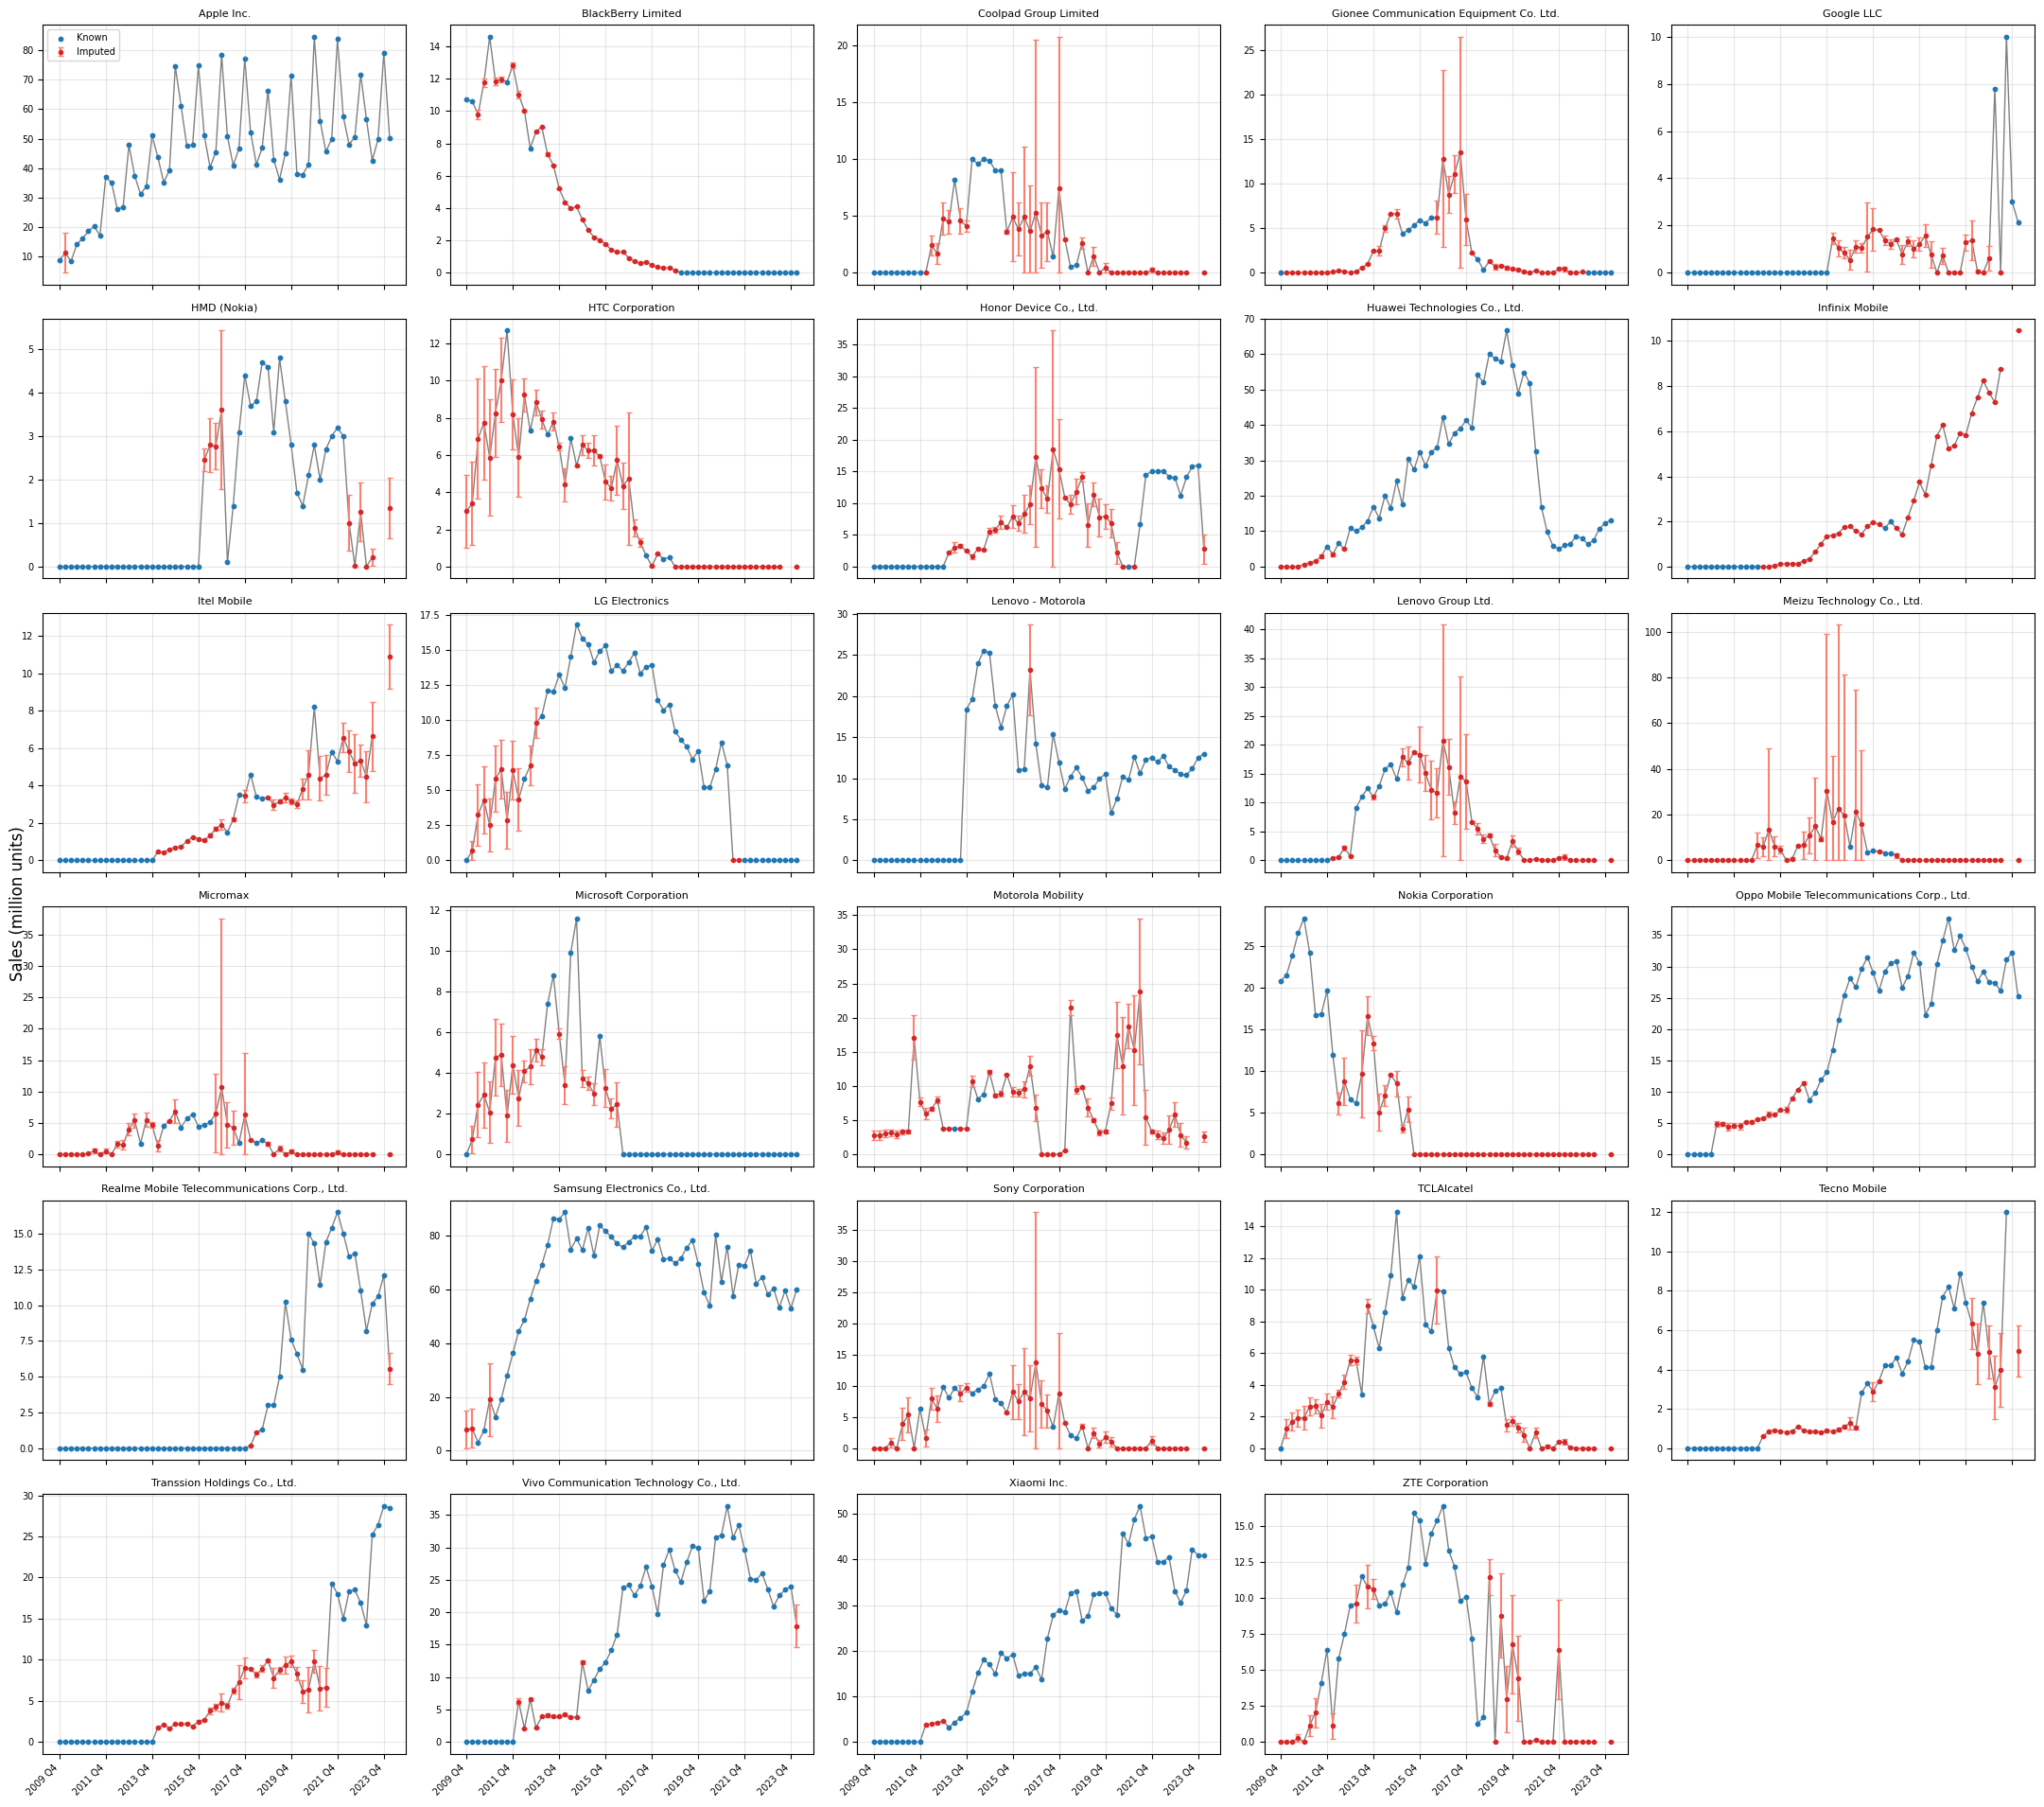

In [4]:
companies = sorted(final["company"].unique())
ncols = 5
nrows = int(np.ceil(len(companies) / ncols))

# quarter labels for the x axis
labels = final.drop_duplicates("id").set_index("id").apply(
    lambda r: f"{int(r['years'])} Q{int(r['quarters'])}", axis=1
)
ids = sorted(final["id"].unique())
ticks = ids[::8]

fig, axes = plt.subplots(nrows, ncols, figsize=(22, 3.2 * nrows), sharex=True)
axes = axes.flatten()

for ax, company in zip(axes, companies):
    g = final[final["company"] == company].sort_values("id")
    known = g[g["sales"].notna()]
    imputed = g[g["imputed"].notna()]

    ax.plot(g["id"], g["sales_filled"], color="gray", lw=1, zorder=1)
    ax.scatter(known["id"], known["sales"], s=10, color="tab:blue", label="Known", zorder=2)
    ax.errorbar(
        imputed["id"], imputed["imputed"],
        yerr=[imputed["imputed"] - imputed["ci_lower"], imputed["ci_upper"] - imputed["imputed"]],
        fmt="o", ms=3, color="tab:red", ecolor="salmon", capsize=2, label="Imputed", zorder=3,
    )

    ax.set_title(company, fontsize=8)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=7)
    ax.set_xticks(ticks)
    ax.set_xticklabels([labels[i] for i in ticks], rotation=45, ha="right")

# hide unused subplots
for ax in axes[len(companies):]:
    ax.axis("off")

axes[0].legend(fontsize=7)
fig.supylabel("Sales (million units)")
plt.tight_layout()
plt.show()



In [5]:
df = pd.read_csv("data.csv")

# add the imputed values (from the LP step) and fill the NaN sales with them
df = df.merge(imp[["id", "company", "imputed"]], on=["id", "company"], how="left")
df["sales_imputed"] = df["sales"].fillna(df["imputed"])
df = df.drop(columns="imputed")

df.to_csv("data.csv", index=False)
print(df.head())

   id  years  quarters                                  company  sales  \
0   4   2009         4                               Apple Inc.    8.7   
1   4   2009         4                       BlackBerry Limited   10.7   
2   4   2009         4                    Coolpad Group Limited    0.0   
3   4   2009         4  Gionee Communication Equipment Co. Ltd.    0.0   
4   4   2009         4                               Google LLC    0.0   

   google_trend_values  sales_imputed  
0                33.67            8.7  
1                74.33           10.7  
2                 2.00            0.0  
3                 3.67            0.0  
4                 5.33            0.0  
